<a href="https://colab.research.google.com/github/Mgourson/IS/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

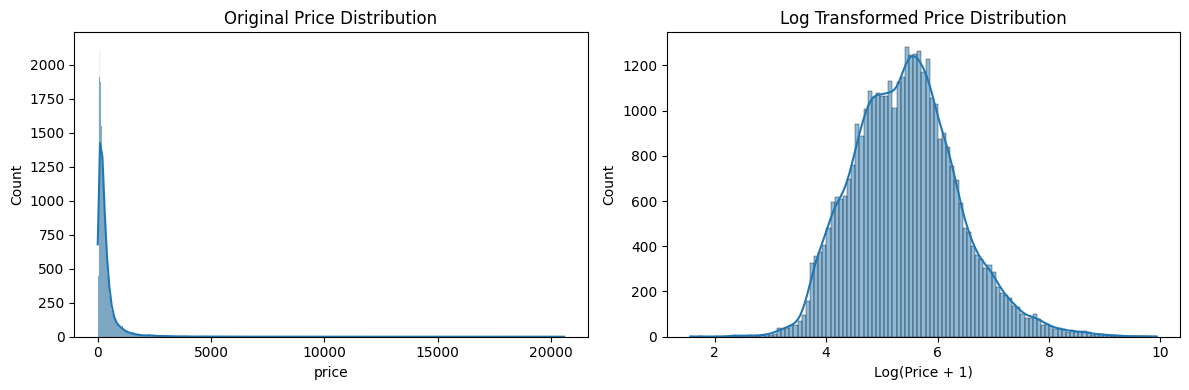

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/cleaned_airbnb_data_6.csv')
price = df.loc[df['price'] > 0, 'price']

# Compare prices before and after the log transformation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(price, kde=True, ax=axes[0])
axes[0].set_title('Original Price Distribution')

sns.histplot(np.log1p(price), kde=True, ax=axes[1])
axes[1].set_title('Log Transformed Price Distribution')
axes[1].set_xlabel('Log(Price + 1)')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response:
1. I examined the price column, which shows each listing’s nightly rate.

2. I used np.log1p(price) to apply a log transformation because the prices were right-skewed. I created side-by-side histograms to compare the original and transformed prices.

3. The transformation reduced the skew and made the typical prices easier to see and compare. This helps stakeholders understand pricing patterns without the most expensive listings dominating the chart.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [10]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Fill missing values with each column's median
columns = ['price', 'minimum_nights']
df[columns] = df[columns].fillna(df[columns].median())

# Scale price and standardize minimum nights
df['price_minmax'] = MinMaxScaler().fit_transform(df[['price']])
df['minimum_nights_standardized'] = StandardScaler().fit_transform(df[['minimum_nights']])

# Compare original and scaled values
display(df[['price', 'price_minmax',
            'minimum_nights', 'minimum_nights_standardized']].head())

,price,price_minmax,minimum_nights,minimum_nights_standardized
0,67.22,0.003083,30.0,0.412750
1,213.56,0.010194,1.0,-0.559496
2,99.63,0.004658,30.0,0.412750
3,95.21,0.004443,30.0,0.412750
4,113.00,0.005308,1.0,-0.559496


### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response:
1. I scaled price using Min-Max scaling, which puts values between 0 and 1. I also standardized minimum_nights, giving it a mean of 0 and a standard deviation of 1.

2. These values can be more useful when grouping similar listings with machine learning. Scaling helps keep larger price values from having too much influence compared to minimum nights.
3. Airbnb’s data analysts could use these values to find groups of listings with similar prices and stay requirements. This could help them understand different types of listings and make better recommendations.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [12]:
# Fill missing review counts with zero
df['number_of_reviews'] = df['number_of_reviews'].fillna(0)

# Group review counts into three quantile-based categories
df['review_volume'] = pd.qcut(df['number_of_reviews'], q=3,labels=['Low', 'Medium', 'High'])

# Check category counts and sample rows
display(df['review_volume'].value_counts())
display(df[['number_of_reviews', 'review_volume']].head(10))

,count
review_volume,
Low,14717
Medium,14613
High,14421


,number_of_reviews,review_volume
0,47,High
1,24,High
2,19,Medium
3,39,High
4,26,High
5,238,High
6,389,High
7,54,High
8,46,High
9,98,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response:
1. I grouped number_of_reviews into three categories: Low, Medium, and High, using quantile-based binning.

2. These groups make it easier to compare listings without looking at every exact review count. They give a simpler view of patterns in the data.

3. Airbnb’s marketing and host support teams could use these groups to identify listings with fewer reviews and offer hosts tips for encouraging guest feedback.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [14]:
# Create a price-to-minimum-nights ratio
df['price_to_minimum_nights'] = (
    df['price'] / df['minimum_nights'].replace(0, np.nan))

# Flag listings requiring stays of at least 30 nights
df['is_long_term_stay'] = df['minimum_nights'] >= 30

display(df[['price', 'minimum_nights',
            'price_to_minimum_nights', 'is_long_term_stay']].head(10))

,price,minimum_nights,price_to_minimum_nights,is_long_term_stay
0,67.22,30.0,2.240667,True
1,213.56,1.0,213.560000,False
2,99.63,30.0,3.321000,True
3,95.21,30.0,3.173667,True
4,113.00,1.0,113.000000,False
5,96.48,31.0,3.112258,True
6,223.67,31.0,7.215161,True
7,198.74,30.0,6.624667,True
8,115.40,30.0,3.846667,True
9,129.91,30.0,4.330333,True


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response:
1. I created price_to_minimum_nights to compare nightly prices relative to minimum stay requirements. I also created is_long_term_stay to flag listings requiring at least 30 nights.

2. Hosts and Airbnb analysts could use these columns to compare listings with different prices and stay requirements.

3. These features could help hosts review their rates and minimum stays. The long-term flag also makes it easier for Airbnb analysts to identify listings suited for monthly stays.

## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [16]:
# One-hot encode room type
room_type_dummies = pd.get_dummies(df['room_type'], prefix='room_type', dtype=int)
df = pd.concat([df, room_type_dummies], axis=1)

# Compare room type with the new columns
display(df[['room_type'] + room_type_dummies.columns.tolist()].head(10))

,room_type,room_type_Entire home/apt,room_type_Entire home/apt,room_type_Hotel room,room_type_Hotel room,room_type_Private room,room_type_Private room,room_type_Shared room,room_type_Shared room
0,Private room,0,0,0,0,1,1,0,0
1,Private room,0,0,0,0,1,1,0,0
2,Entire home/apt,1,1,0,0,0,0,0,0
3,Private room,0,0,0,0,1,1,0,0
4,Private room,0,0,0,0,1,1,0,0
5,Private room,0,0,0,0,1,1,0,0
6,Private room,0,0,0,0,1,1,0,0
7,Private room,0,0,0,0,1,1,0,0
8,Entire home/apt,1,1,0,0,0,0,0,0
9,Entire home/apt,1,1,0,0,0,0,0,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response:
1. I encoded room_type to turn the text categories into numbers that a pricing model can use.

2. I used one-hot encoding with pd.get_dummies to create a separate 0 or 1 column for each room type. This avoids giving the categories an artificial ranking.

3. These columns could help a pricing model estimate how room type relates to price, such as differences between an entire home and a private room.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [29]:
# Export the fully transformed dataset to a CSV file
df.to_csv('cleaned_airbnb_data_7.csv', index=False)
print("Dataset successfully saved as cleaned_airbnb_data_7.csv")

Dataset successfully saved as cleaned_airbnb_data_7.csv


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response:

1. Scaling felt most important because it helps keep larger price values from having too much influence when a model compares listings.

2. review_volume and is_long_term_stay make it easier for hosts and analysts to group listings by review counts and stay requirements.

3. I would build a dashboard with a map showing listing prices and filters for room type, review volume, and long-term stays.

4. This connects to my goal of preparing data for business analysis. I practiced turning raw data into useful features for comparing listings and supporting decisions.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [30]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 394712 bytes to assignment_07_data_transformation.html
